# Tip-of-the-Tongue Book Finder

Hybrid search (BM25 + dense embeddings + cross-encoder reranker) over the CMU Book Summary Dataset.

**Notebook outline**
1. Load and inspect the data
2. Gold test set (60 queries)
3. BM25 baseline
4. Dense search
5. Fusion and reranker
6. Evaluation table

The API and frontend live in `app/`. This notebook is for exploration and experiments only.

## 1. Load and inspect the data

The dataset is a tab-separated file with no header row. The column names come from the dataset's README: Wikipedia ID, Freebase ID, title, author, publication date, genres (a JSON string) and the plot summary.

`quoting=3` tells pandas to treat quote characters as normal text, because plot summaries contain a lot of them.

In [1]:
import json
import pandas as pd
from pathlib import Path

PATH = Path("../data/raw/booksummaries/booksummaries.txt")
print("file found:", PATH.exists())

COLS = ["wiki_id", "freebase_id", "title", "author", "pub_date", "genres", "summary"]
df = pd.read_csv(PATH, sep="\t", header=None, names=COLS, quoting=3)
df.shape

file found: True


(16559, 7)

### Clean the genres and measure summary length

The genres column holds JSON like `{"/m/06nbt": "Satire"}`. We keep only the readable names and join them with " | ".

We also add `summary_words`. Summary length matters later because embedding models cut off long texts.

In [2]:
df["genres"] = df["genres"].apply(
    lambda s: " | ".join(json.loads(s).values()) if isinstance(s, str) else ""
)
df["summary_words"] = df["summary"].str.split().str.len()
df.head(3)

,wiki_id,freebase_id,title,author,pub_date,genres,summary,summary_words
0,620,/m/0hhy,Animal Farm,George Orwell,1945-08-17,Roman à clef | Satire | Children's literature ...,"Old Major, the old boar on the Manor Farm, ca...",957
1,843,/m/0k36,A Clockwork Orange,Anthony Burgess,1962,Science Fiction | Novella | Speculative fictio...,"Alex, a teenager living in near-future Englan...",998
2,986,/m/0ldx,The Plague,Albert Camus,1947,Existentialism | Fiction | Absurdist fiction |...,The text of The Plague is divided into five p...,1119


### Inspect: missing values, lengths, duplicates

Checking three things before building anything:
- which columns have missing values
- how long the summaries are (this decides how we embed them)
- how many titles appear more than once (these will be near-duplicates for the reranker)

In [3]:
print("missing values per column:")
print(df.isna().sum())
print("\nsummary length in words:")
print(df["summary_words"].describe())
print("\nduplicate titles:", df["title"].duplicated().sum())
df[["title", "author", "genres"]].sample(5, random_state=1)

missing values per column:
wiki_id             0
freebase_id         0
title               0
author           2382
pub_date         5610
genres              0
summary             0
summary_words       0
dtype: int64

summary length in words:
count    16559.000000
mean       429.202126
std        500.339692
min          1.000000
25%        120.000000
50%        263.000000
75%        569.000000
max      10334.000000
Name: summary_words, dtype: float64

duplicate titles: 282


,title,author,genres
10091,Echo Park,Michael Connelly,Crime Fiction | Mystery | Fiction | Suspense
10761,Saints of Big Harbour,NaN,
5039,Engine Summer,John Crowley,Science Fiction | Speculative fiction
4382,The Staircase,Ann Rinaldi,Children's literature | Historical fiction | S...
1610,Hornet Flight,Ken Follett,Thriller | Young adult literature | Fiction


### What does one record look like?

Each row is one book. Below is the first book (*Animal Farm*) shown as a column-by-column list, with the summary cut to 300 characters so it fits on screen.

In [4]:
pd.set_option("display.max_colwidth", 120)

row = df.iloc[0].copy()
row["summary"] = row["summary"][:300] + " ..."
row

wiki_id                                                                                                                              620
freebase_id                                                                                                                      /m/0hhy
title                                                                                                                        Animal Farm
author                                                                                                                     George Orwell
pub_date                                                                                                                      1945-08-17
genres                                                     Roman à clef | Satire | Children's literature | Speculative fiction | Fiction
summary           Old Major, the old boar on the Manor Farm, calls the animals on the farm for a meeting, where he compares the human...
summary_words                            

### Column overview

For every column: its data type, how many values are missing, and how many distinct values it has.

Note that `genres` shows 0 missing because an empty genre list was stored as an empty string, not as NaN. We count those separately in the genre section below.

In [5]:
pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "distinct_values": df.nunique(),
})

,dtype,missing,missing_%,distinct_values
wiki_id,int64,0,0.0,16559
freebase_id,str,0,0.0,16559
title,str,0,0.0,16277
author,str,2382,14.4,4714
pub_date,str,5610,33.9,2639
genres,str,0,0.0,2155
summary,str,0,0.0,16532
summary_words,int64,0,0.0,1885


### Summary length

Summary length matters for two reasons:
- **Dense search:** embedding models read only the first few hundred tokens. One word is roughly 1.3 tokens, so anything much beyond 200 words is partly invisible to the model.
- **BM25:** long documents contain more words, so they match more queries by chance. BM25 corrects for this, but it is worth knowing how extreme the lengths are.

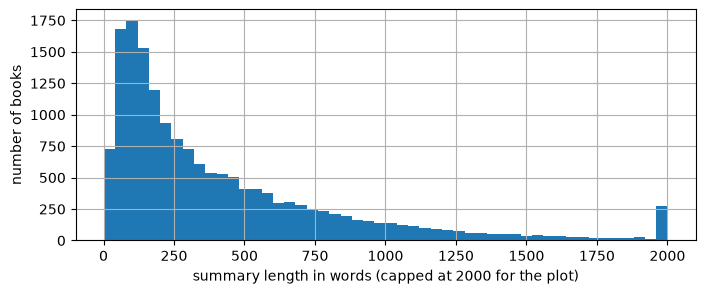

under   20 words:    203 (1%)   over   20 words:  16323 (99%)
under  200 words:   6859 (41%)   over  200 words:   9670 (58%)
under 1000 words:  14956 (90%)   over 1000 words:   1602 (10%)


In [6]:
import matplotlib.pyplot as plt

ax = df["summary_words"].clip(upper=2000).hist(bins=50, figsize=(8, 3))
ax.set_xlabel("summary length in words (capped at 2000 for the plot)")
ax.set_ylabel("number of books")
plt.show()

n = len(df)
for limit in (20, 200, 1000):
    shorter = (df["summary_words"] < limit).sum()
    longer = (df["summary_words"] > limit).sum()
    print(f"under {limit:>4} words: {shorter:>6} ({shorter/n:.0%})   over {limit:>4} words: {longer:>6} ({longer/n:.0%})")

### The shortest summaries

Some summaries are only a few words long. These books have almost no text to search, so they will be hard for every method. It is worth knowing which ones they are before we write test queries.

In [7]:
df.nsmallest(8, "summary_words")[["title", "author", "summary_words", "summary"]]

,title,author,summary_words,summary
5693,The Deathlord of Ixia,John Grant,1,==Receptio
5879,The Caverns of Kalte,Joe Dever,1,==Receptio
5972,The Eyes of Darkness,Dean Koontz,1,==Character
11215,Chucaro: Wild Pony of the Pampa,Francis Kalnay,1,==Reference
15789,Lurulu,Jack Vance,1,==Reference
16531,Guardians of Ga'Hoole Book 4: The Siege,Helen Dunmore,1,==Receptio
3879,Slavers,Chris Pramas,2,==Publication histor
5271,Golem in the Gears,Piers Anthony,2,pl:Zakochany golem


### Genres

Each book can have several genres. We split them into one row per genre to count them. Books with no genre label are counted separately.

books with no genre: 3718
distinct genres: 227


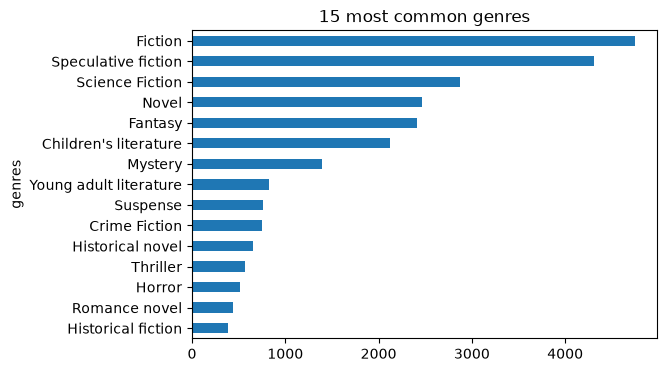

In [8]:
genre_counts = (
    df["genres"].str.split(" | ", regex=False).explode()
    .loc[lambda s: s != ""]
    .value_counts()
)
print("books with no genre:", (df["genres"] == "").sum())
print("distinct genres:", len(genre_counts))

genre_counts.head(15).sort_values().plot.barh(figsize=(6, 4), title="15 most common genres")
plt.show()

### Publication years and authors

Publication dates come in mixed formats (`1945-08-17`, `1962`), so we keep only the first four characters as the year. A large share of dates is missing.

We also check which authors appear most often. Prolific authors and book series are where near-duplicate summaries come from.

count    10949.0
mean      1976.0
std         50.0
min        398.0
25%       1966.0
50%       1991.0
75%       2003.0
max       2013.0
Name: year, dtype: float64


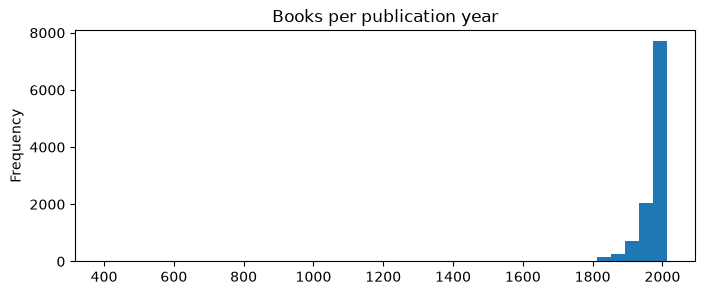


Top 10 authors by number of books:
author
Agatha Christie         74
Franklin W. Dixon       68
K. A. Applegate         62
Stephen King            60
Edgar Rice Burroughs    59
Ruth Rendell            55
John Dickson Carr       55
P. G. Wodehouse         50
Orson Scott Card        49
Harry Turtledove        49
Name: count, dtype: int64


In [9]:
df["year"] = pd.to_numeric(df["pub_date"].astype(str).str[:4], errors="coerce")

print(df["year"].describe().round(0))
df["year"].dropna().astype(int).plot.hist(bins=40, figsize=(8, 3), title="Books per publication year")
plt.show()

print("\nTop 10 authors by number of books:")
print(df["author"].value_counts().head(10))

### Duplicate titles

282 titles appear more than once. These are either different books sharing a title or the same book listed twice. They matter later because the reranker has to tell them apart.

In [10]:
dups = df[df["title"].duplicated(keep=False)].sort_values("title")
dups[["title", "author", "pub_date", "summary_words"]].head(12)

,title,author,pub_date,summary_words
10023,1945,Robert Conroy,2007-05-29,123
7680,1945,William R. Forstchen,1995-08-01,446
15495,A Casa,Miguel M. Abrahão,NaN,115
16330,A Casa,Andre Vianco,NaN,38
6653,A Taste for Death,Peter O'Donnell,NaN,256
9020,A Taste for Death,P. D. James,1986,54
15682,Abduction,Robin Cook,2000,286
5668,Abduction,Peg Kehret,2004-11,122
13007,American Beauty,Edna Ferber,1931,227
12061,American Beauty,Allen Steele,2006-09-06,165


### Findings so far

- Some summaries are leftover Wikipedia markup (`==Reception`, `pl:Zakochany golem`), not plot text.
- 58% of summaries are longer than 200 words, so a 256-token embedding model will not see the end of most plots.
- Titles are not unique (282 repeats are different books), so `wiki_id` is the row identifier.
- A few summaries are shared by several rows.
- Author (14%), date (34%) and genre (22%) are often missing. This does not block search, but the UI needs fallbacks.

Next we measure how widespread the markup and duplicate problems are, so the cleaning rules are based on data and not on guesses.

### How many summaries contain Wikipedia markup?

We count summaries that contain four typical markup patterns: section headings (`==`), language prefixes (`pl:`), wiki links (`[[`, `{{`) and HTML leftovers (`<ref`, `&nbsp;`).
                                                                                                                                      
                                                                                                            

In [12]:
import re

patterns = {
    "heading markup (==)": r"==",
    "language prefix (pl:)": r"^[a-z]{2,3}:",
    "wiki links ([[ or {{)": r"\[\[|\{\{",
    "html leftovers": r"<ref|<br|&nbsp;|&amp;",
}
for name, pat in patterns.items():
    mask = df["summary"].str.contains(pat, regex=True)
    print(f"{name:26} {mask.sum():>6} books")

has_heading = df["summary"].str.contains("==", regex=False)
df[has_heading][["title", "summary_words", "summary"]].sample(5, random_state=1)                                                                                                                           

heading markup (==)            48 books
language prefix (pl:)           0 books
wiki links ([[ or {{)           6 books
html leftovers                223 books


,title,summary_words,summary
12932,The Story of Edgar Sawtelle,7,=== What Hands Do Chequamegon Poison ===
8829,Kai Lung Unrolls His Mat,649,"Kai Lung adventures usually serve as mere excuses to bring up side stories along the way, which typically take up t..."
15671,Fear,451,"JJ, who works at a restaurant managed by Florian, meets with a group of kids hanging out at the parking lot of the ..."
14744,The Ghost-Seer,61,The work is narrated in the first person by the 'Graf von O**' (Count of O**). It describes the story of a German p...
1024,Oahspe: A New Bible,751,"Oahspe includes doctrinal books, and precepts for behavior can be found throughout its many books. Freedom and resp..."


### Duplicate summaries

Some rows share exactly the same summary text. If they are different books, that is a data error. If they are the same book listed twice, we should keep only one.

In [13]:
dup_sum = df[df["summary"].duplicated(keep=False)].sort_values("summary")
print(len(dup_sum), "rows share their summary with at least one other row")
dup_sum[["title", "author", "summary_words"]].head(10)

37 rows share their summary with at least one other row


,title,author,summary_words
16531,Guardians of Ga'Hoole Book 4: The Siege,Helen Dunmore,1
5693,The Deathlord of Ixia,John Grant,1
5879,The Caverns of Kalte,Joe Dever,1
15789,Lurulu,Jack Vance,1
11215,Chucaro: Wild Pony of the Pampa,Francis Kalnay,1
7817,Conviction,Richard North Patterson,11
10511,Nothing to Lose,Lee Child,11
13381,Beyond Thirty and The Man-Eater,Edgar Rice Burroughs,7
16161,The Oakdale Affair and The Rider,Edgar Rice Burroughs,7
6622,The Saint in Pursuit,Leslie Charteris,3


### Short but not empty: where to draw the line?

Summaries under 20 words are clearly broken. But what about 20 to 60 words? We read a random sample to decide whether they are real plot summaries.

In [14]:
mid = df[df["summary_words"].between(20, 60)]
print(len(mid), "books between 20 and 60 words")
mid.sample(8, random_state=1)[["title", "summary_words", "summary"]]

1318 books between 20 and 60 words


,title,summary_words,summary
6206,All-Consuming Fire,39,Sherlock Holmes finds himself united with the Seventh Doctor to solve the mystery of the theft of arcane tomes from...
8736,The Risk Pool,28,"The plot follows narrator Ned Hall through four periods of his life, focusing specifically on Hall's relationship w..."
13525,No One Thinks Of Greenland,30,The book is set after the Korean War. The novel follows the misadventures of the character Rudy Spruance who has be...
13069,Edith's Diary,53,"When Edith Howland's husband abandons her for a younger woman, leaving her with their alcoholic son and his senile ..."
3767,Julie of the Wolves,27,"The story has three parts, from her present situation (Amaroq, the Wolf), then a flashback (Miyax, the Girl), and f..."
14785,Wolf's Blood,35,"It is revealed here that Blind Seer is a Once Dead sorcerer himself, which explains his blue eyes. One of the twins..."
13347,A Writing Kind of Day,30,"A young writer's experiences are described in twenty seven mostly free verse poems. Topics included are roadkill, V..."
12612,Mutiny on the Enterprise,50,A much needed peace mission to the Orion Arm is delayed when the Enterprise becomes damaged while in orbit around a...


## 2. Cleaning

Decisions, based on the inspection above:

1. **Strip Wikipedia markup** from summaries: HTML tags, `{{templates}}`, `[[wiki links]]` (keeping the visible text), `==headings==`, and HTML entities such as `&amp;`.
2. **Drop summaries under 20 words.** The shortest ones are markup fragments (`==Receptio`), and 20 to 60 word summaries are real, if short, plot descriptions.
3. **Keep missing authors, dates and genres as missing.** They are not needed for search, and filling them with "Unknown" would put fake words into the search index. The UI will show a fallback instead.
4. **Use `wiki_id` as the row identifier**, because titles are not unique.

The original text is kept in `summary_raw` during cleaning, so we can compare before and after.

In [15]:
import html

def clean_summary(text):
    text = re.sub(r"<[^>]+>", " ", text)                           # html tags like <ref>, <br>
    text = re.sub(r"\{\{.*?\}\}", " ", text)                       # {{templates}}
    text = re.sub(r"\[\[(?:[^|\]]*\|)?([^\]]*)\]\]", r"\1", text)  # [[link|text]] -> text
    text = re.sub(r"={2,}[^=]{0,100}={2,}", " ", text)             # ==Heading==
    text = re.sub(r"={2,}", " ", text)                             # leftover == fragments
    text = html.unescape(text)                                     # &amp; -> &
    return re.sub(r"\s+", " ", text).strip()

def context(text, pat, width=50):
    m = re.search(pat, text)
    return text[max(0, m.start() - width): m.end() + width] if m else ""

html_pat = r"<ref|<br|&nbsp;|&amp;"
wiki_pat = r"\[\[|\{\{"

df["summary_raw"] = df["summary"]

# look at the raw text around the markup before changing anything
print("--- html leftovers, before cleaning (5 random examples) ---")
for t in df[df["summary_raw"].str.contains(html_pat)].sample(5, random_state=1)["summary_raw"]:
    print("*", context(t, html_pat))

print("\n--- wiki links, before cleaning ---")
for t in df[df["summary_raw"].str.contains(wiki_pat)]["summary_raw"]:
    print("*", context(t, wiki_pat))

--- html leftovers, before cleaning (5 random examples) ---
* rmany. The biplane, with its top speed of just 103&nbsp;mph, is strafing the runways and destroying multim
* oks combined are estimated to have earned over $30&nbsp;million for Comic Relief. The two books have since
* el, where Stephen finds comfort in Barbara Berrill&nbsp;– a girl Stephen's age living in his neighbourhood
* ter him into accepting the offer (see "Quotes", p.&nbsp;163) - an attempt that doesn't work. The Prince ex
* and kills her. Most of the actors don't fight back&nbsp;— thinking this is a plot change&nbsp;— but soon r

--- wiki links, before cleaning ---
* i-lan has an older brother who has been living in [[United States for a few years. He has a friend wri
*  equal to its supply price.&#34; *Chapter 11. The [[marginal efficiency of capital]] *Chapter 12. The 
* ere is an abandoned one named The Grubber (an old [[English word for sweet shop) near where he lives. 
* ds to go back and witness Jackie Robinson

### Apply the cleaning and drop the broken rows

After cleaning, the word count is recomputed. This matters because a summary that is mostly markup can fall under the 20-word limit only after the markup is removed. Dropped rows are kept in `dropped` so nothing disappears without a record.

In [16]:
MIN_WORDS = 20

df["summary"] = df["summary_raw"].apply(clean_summary)
df["summary_words"] = df["summary"].str.split().str.len()

print("summaries changed by cleaning:", (df["summary"] != df["summary_raw"]).sum())

dropped = df[df["summary_words"] < MIN_WORDS]
df = df[df["summary_words"] >= MIN_WORDS].reset_index(drop=True)

print("dropped (under 20 words):", len(dropped))
print("remaining books:", len(df))

summaries changed by cleaning: 16555
dropped (under 20 words): 203
remaining books: 16356


### Check the result

Three checks: the markup patterns should be gone, the shortest remaining summaries should be real text, and we count the duplicate summaries again.

In [17]:
for name, pat in {"headings": r"==", "html": html_pat, "wiki links": wiki_pat}.items():
    print(f"{name:12} remaining: {df['summary'].str.contains(pat).sum()}")

print("\nduplicate summaries now:", df["summary"].duplicated(keep=False).sum(), "rows")
print("\nshortest remaining summaries:")
df.nsmallest(5, "summary_words")[["title", "author", "summary_words", "summary"]]

headings     remaining: 0
html         remaining: 1
wiki links   remaining: 5

duplicate summaries now: 0 rows

shortest remaining summaries:


,title,author,summary_words,summary
1303,"A Child Called ""It""",Dave Pelzer,20,The book is written as a memoir which covers physical and emotional abuse between Dave Pelzer and his biological mot...
3227,The Secret of Wildcat Swamp,Franklin W. Dixon,20,An paleontology expedition in the West turns into a desperate attempt to capture freight train robbers and an escape...
5684,The Witch Hunters,Steve Lyons,20,"In Salem Village, Massachusetts, 1692, the Doctor and his companions become immeshed in the tragedy of the Salem wit..."
6505,No Future,Paul Cornell,20,"London, 1976, while Bernice becomes lead singer in a punk band, the Doctor must face more than one old enemy..."
6538,Revolution Man,Paul Leonard,20,The Doctor tries to stop a mysterious entity called The Revolution Man from spreading mind altering drugs in the 1960s.


### Sanity checks on the cleaning

Two things to verify:
- Nearly every summary was reported as "changed". We check how many changed by more than whitespace. If the answer is a few hundred, the cleaning only touched what it should.
- A handful of malformed wiki links (`[[United States` with no closing brackets) and one html match survived. We look at the html match, then remove leftover `[[` and `]]` characters.

In [18]:
collapse_ws = lambda s: re.sub(r"\s+", " ", s).strip()

changed_beyond_ws = df["summary"] != df["summary_raw"].apply(collapse_ws)
print("changed beyond whitespace:", changed_beyond_ws.sum())

print("\nremaining html match:")
for t in df[df["summary"].str.contains(html_pat)]["summary"]:
    print("*", context(t, html_pat))

changed beyond whitespace: 916

remaining html match:
* ket knife, and a 6-shot .45 revolver. Plot summary<ref name="Chad Oliver 1952"/


In [19]:
def clean_summary(text):
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\{\{.*?\}\}", " ", text)
    text = re.sub(r"\[\[(?:[^|\]]*\|)?([^\]]*)\]\]", r"\1", text)
    text = re.sub(r"={2,}[^=]{0,100}={2,}", " ", text)
    text = re.sub(r"={2,}", " ", text)
    text = html.unescape(text)
    text = text.replace("[[", "").replace("]]", "")   # malformed leftovers
    return re.sub(r"\s+", " ", text).strip()

df["summary"] = df["summary_raw"].apply(clean_summary)
df["summary_words"] = df["summary"].str.split().str.len()

print("rows now under 20 words:", (df["summary_words"] < MIN_WORDS).sum())
print("wiki-link leftovers:", df["summary"].str.contains(r"\[\[|\]\]").sum())
print("remaining books:", len(df))

rows now under 20 words: 0
wiki-link leftovers: 0
remaining books: 16356


### Save the cleaned dataset

The cleaned table is saved as a Parquet file (compact, keeps column types). The raw download stays out of git, but this cleaned file is committed, so anyone can reproduce the results without re-running the cleaning.

In [21]:
OUT = Path("../data/processed/books_clean.parquet")
OUT.parent.mkdir(parents=True, exist_ok=True)

cols = ["wiki_id", "title", "author", "pub_date", "genres", "summary", "summary_words"]
df[cols].to_parquet(OUT, index=False)

print(f"saved {len(df)} books, {OUT.stat().st_size / 1e6:.1f} MB")

saved 16356 books, 26.0 MB
